<a href="https://colab.research.google.com/github/villsydican/machine-learning-project/blob/main/Chart_annalysis_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import io
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from google.auth import default
from PIL import Image

# 1. Authenticate & Build Drive API
auth.authenticate_user()
creds, _ = default()
drive_service = build('drive', 'v3', credentials=creds)

# 2. Path to your manually created dataset folder
output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

def download_and_slice(file_id, file_name, rows, cols, label_mapping, prefix):
    print(f"📥 Downloading: {file_name}...")
    request = drive_service.files().get_media(fileId=file_id)
    local_path = f"/tmp/{file_id}.jpg"

    with open(local_path, 'wb') as fh:
        downloader = MediaIoBaseDownload(fh, request)
        done = False
        while not done:
            status, done = downloader.next_chunk()

    img = Image.open(local_path).convert('RGB')
    w, h = img.size
    cell_w, cell_h = w / cols, h / rows
    count = 0

    for r in range(rows):
        for c in range(cols):
            label = label_mapping.get((r, c))
            if not label:
                continue
            crop = img.crop((
                int((c + 0.08) * cell_w), int((r + 0.18) * cell_h),
                int((c + 0.92) * cell_w), int((r + 0.78) * cell_h)
            )).resize((128, 128))

            save_path = os.path.join(output_dir, label, f"{prefix}_r{r}_c{c}.jpg")
            crop.save(save_path)
            count += 1

    print(f"✅ Sliced & sorted {count} tiles from {file_name}")

# 3. Process each sheet into your manual folders
download_and_slice(
    "1BViimj3mJ-lnL-M79d0QkfOv56AX2BrK", "Bullish candlestick pattern.jpg",
    3, 3, {(r, c): 'buy' for r in range(3) for c in range(3)}, "bullish_9"
)

download_and_slice(
    "1Vkj8OA80pGCvJO8sIN1QY_MP9jEHB1yA", "Candlestick signals",
    2, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'sell', (0,3): 'sell', (1,0): 'buy', (1,1): 'buy', (1,2): 'buy', (1,3): 'hold'}, "signals_8"
)

download_and_slice(
    "1GLPPljf91i74zHnMfGtUixI4g8CoIyZr", "TRADING PSYCHOLOGY.jpg",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'sell', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'sell', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "psych_16"
)

download_and_slice(
    "1kj43Dk9YyS9stuEWuG70bDoAbOY7PpmO", "Take Your Binary Options Trading",
    4, 4, {(0,0): 'buy', (0,1): 'sell', (0,2): 'buy', (0,3): 'buy', (1,0): 'sell', (1,1): 'buy', (1,2): 'sell', (1,3): 'sell', (2,0): 'buy', (2,1): 'sell', (2,2): 'buy', (2,3): 'sell', (3,0): 'buy', (3,1): 'sell', (3,2): 'buy', (3,3): 'sell'}, "binary_16"
)

download_and_slice(
    "15sUVHLacRm-3-AzpLHP0CwswZl22p2bD", "Trade Smarter with Our Binary Options Strategy PDF.jpg",
    3, 5, {(r, c): 'sell' for r in range(3) for c in range(5)}, "bearish_15"
)

print("\n🎉 Population complete! Folder counts:")
for cls in ['buy', 'sell', 'hold']:
    print(f"📂 {cls}/ -> {len(os.listdir(os.path.join(output_dir, cls)))} images")

📥 Downloading: Bullish candlestick pattern.jpg...
✅ Sliced & sorted 9 tiles from Bullish candlestick pattern.jpg
📥 Downloading: Candlestick signals...
✅ Sliced & sorted 8 tiles from Candlestick signals
📥 Downloading: TRADING PSYCHOLOGY.jpg...
✅ Sliced & sorted 16 tiles from TRADING PSYCHOLOGY.jpg
📥 Downloading: Take Your Binary Options Trading...
✅ Sliced & sorted 16 tiles from Take Your Binary Options Trading
📥 Downloading: Trade Smarter with Our Binary Options Strategy PDF.jpg...
✅ Sliced & sorted 15 tiles from Trade Smarter with Our Binary Options Strategy PDF.jpg

🎉 Population complete! Folder counts:
📂 buy/ -> 1027 images
📂 sell/ -> 1036 images
📂 hold/ -> 1001 images


In [4]:
#Generating the images using python
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

output_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
for cls in ['buy', 'sell', 'hold']:
  os.makedirs(os.path.join(output_dir, cls), exist_ok=True)

def render_candles(candles, save_path, dark_mode=False):
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  bg_color = '#12161c' if dark_mode else '#ffffff'
  bull_color = '#26a69a' if dark_mode else '#16a34a'
  bear_color = '#ef5350' if dark_mode else '#dc2626'
  fig.patch.set_facecolor(bg_color)
  ax.set_facecolor(bg_color)
  for idx, (o, h, l, c) in enumerate(candles):
    color = bull_color if c >= o else bear_color
    #Wick generation
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    #Body generation
    lower = min(o, c)
    height = max(abs(c - o), 0.15) #Minimum visible thickness for Doji
    react = Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(react)
  all_lows = [x[2] for x in candles]
  all_highs = [x[1] for x in candles]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(save_path, dpi=100, facecolor=bg_color)
  plt.close(fig)

# Pattern Generators (each building 4 trend candles + key signal candle)
def generate_buy_pattern():
  pattern_type = random.choice(['hammer', 'bullish_engulfing', 'morning_star', 'three_white_soldiers'])
  price = random.uniform(50, 100)
  candles = []
  if pattern_type == 'hammer':
    # 4 bearish downtrend candles + long lower-wick hammer
    for _ in range (4):
      o = price
      c = o - random.uniform(1.2, 3.0)
      h = o + random.uniform(0.2, 1.0)
      l = c - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c))
      price = c
    o = price
    c = o + random.uniform(0.4, 1.2)
    h = c + random.uniform(0.0, 0.3)
    l = o - random.uniform(3.5, 6.5)
    candles.append ((o, h, l, c))
  elif pattern_type == 'bullish_engulfing':
    # 3 downtrend + 1 small red + 1 large green engulfing candle
    for _ in range (3):
      o = price
      c = o - random.uniform(1.0, 2.5)
      candles.append((o, o + 0.6, c - 0.6, c))
      price = c
    o1 = price
    c1 = o1 - random.uniform(0.8, 1.6)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.1, 0.4)
    c2 = o1 + random.uniform(1.0, 2.5)
    candles.append((o2, c2 + 0.5, o2 - 0.4, c2))

  elif pattern_type == 'morning_star':
    # 2 downtrend + 1 big red + 1 small star + big green
    for _ in range (2):
      o = price
      c = o - random.uniform(1.0, 2.0)
      candles.append ((o, o + 0.5, c - 0.5, c))
      price = c
    o1, c1 = price, price - random.uniform(2.5, 4.0)
    candles.append((o1, o1 + 0.4, c1 - 0.4, c1))
    o2 = c1 - random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = max(o2, c2) + 0.2
    c3 = o1 - random.uniform(0.0, 0.8)
    candles.append((o3, c3 + 0.5, o3 - 0.3, c3))
  else: # drawing three white soldiers
    for _ in range (2):
      o = price
      c = o - random.uniform(1.2, 2.5)
      candles.append((o, o + 0.5, c - 0.5, c))
      price = c
    for _ in range (3):
      o = price + random.uniform(0.1, 0.4)
      c = o + random.uniform(1.8, 3.2)
      candles.append((o, c + 0.4, o - 0.3, c))
      price = c

  return candles

def generate_sell_pattern():
  pattern_type = random.choice(['shooting_star', 'bearish_engulfing', 'evening_star', 'three_black_crows'])
  price = random.uniform(50, 100)
  candles = []

  if pattern_type == 'shooting_star':
    for _ in range(4):
      o = price
      c = o + random.uniform(1.2, 3.0)
      h = c + random.uniform(0.2, 1.0)
      l = o - random.uniform(0.2, 1.0)
      candles.append((o, h, l, c ))
      price = c
    o = price
    c  = o - random.uniform(0.4, 1.2)
    h = o + random.uniform(3.5, 6.5)
    l = c - random.uniform(0.0, 0.3)
    candles.append((o, h, l, c))
  elif pattern_type == 'bearish_engulfing' :
    for _ in range (3):
      o = price
      c = o + random.uniform(1.0, 2.5)
      candles.append((o, c + 0.6, o - 0.6, c))
      price = c
    o1 =  price
    c1 = o1 + random.uniform(0.8, 1.6)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1 ))
    o2 = c1 + random.uniform(0.1, 0.4)
    c2 = o1 - random.uniform(1.0, 2.5)
    candles.append((o2, o2 + 0.4, c2 - 0.5, c2))
  elif pattern_type == 'evening_star':
    for _ in range(2):
      o = price
      c = o + random.uniform(1.0, 2.0)
      candles.append((o, c + 0.5, o - 0.5, c)) # Fixed undefined o1 to o
      price = c
    o1, c1 = price, price + random.uniform(2.5, 4.0)
    candles.append((o1, c1 + 0.4, o1 - 0.4, c1))
    o2 = c1 + random.uniform(0.2, 0.6)
    c2 = o2 + random.uniform(-0.3, 0.3)
    candles.append((o2, max(o2, c2) + 0.7, min(o2, c2) - 0.7, c2))
    o3 = min(o2, c2) - 0.2
    c3 = o1 + random.uniform(0.0, 0.8)
    candles.append((o3, o3 + 0.3, c3 - 0.5, c3))
  else : # three_black_crows
    for _ in range (2):
      o = price
      c = o + random.uniform(0.1, 0.4)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
    for _ in range(3):
      o = price - random.uniform(0.1, 0.4)
      c = o - random.uniform(1.8, 3.2)
      candles.append((o, o + 0.3, c - 0.4, c))
      price = c
  return candles

# Generating images for holding or equilibrium patterns
# Sideways consolidation with dojis and Spinning tops
def generate_hold_pattern():
  base_price = random.uniform(50, 100 )
  candles = []
  for _ in range(5):
    o = base_price + random.uniform(-0.8, 0.8)
    c = o + random.uniform(-0.4, 0.4)
    h = max(o, c) + random.uniform(0.8, 2.2)
    l = min(o, c) - random.uniform(0.8, 2.2)
    candles.append((o, h, l, c))
  return candles

# Generating 200 images per class
samples_per_class = 1000
print (f"Generating {samples_per_class * 3} synthetic candlestick images.....")

for i in range (samples_per_class):
  dark = random.choice([True, False]) # Mixing the light and dark trading themes
  render_candles(generate_buy_pattern(), os.path.join(output_dir, 'buy', f'synth_buy_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_sell_pattern(), os.path.join(output_dir, 'sell', f'synth_sell_{i:03d}.png'), dark_mode=dark)
  render_candles(generate_hold_pattern(), os.path.join(output_dir, 'hold', f'synth_hold_{i:03d}.png'), dark_mode=dark)
print ("===========================")
print ("\n Synthetic dataset generation complet!! Updated Folde Total: ")
for cls in ['buy', 'sell', 'hold']:
  total = len(os.listdir(os.path.join(output_dir, cls)))
  print(f"{cls}/ -> {total} total images")

Generating 3000 synthetic candlestick images.....

 Synthetic dataset generation complet!! Updated Folde Total: 
buy/ -> 1027 total images
sell/ -> 1036 total images
hold/ -> 1001 total images


In [5]:
#MODEL TRAINING AND VALIDATION
import tensorflow as tf
data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
batch_size = 16
img_height, img_width = 128, 128
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset = "training",
    seed = 123,
    image_size = (img_height, img_width),
    batch_size = batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure




)
#loading the validation Dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode = 'categorical'#converting the data into one-hot-encoded structure
)
class_names = train_ds.class_names
print (f"\n Detected Model Classes : {class_names}")


Found 3064 files belonging to 3 classes.
Using 2452 files for training.
Found 3064 files belonging to 3 classes.
Using 612 files for validation.

 Detected Model Classes : ['buy', 'hold', 'sell']


In [6]:
#MODEL TRAINING AND EXECUTION
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, kernel_size=3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')#output layer


])
#Compling the model
model.compile(
    optimizer='adam',
    loss = 'categorical_crossentropy',
    metrics=['accuracy']
)
#Printing the summary of the model layers and tool parameters
model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
#Training and testing the model performances
epochs = 15
print (f"Starting training for {epochs} epochs....\n")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
print ("\Training completed!!!!")
model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model.save(model_path)
print(f"Model saved to: {model_path} Successfully")

Starting training for 15 epochs....

Epoch 1/15


<>:9: SyntaxWarning: invalid escape sequence '\T'
<>:9: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_12446/364429844.py:9: SyntaxWarning: invalid escape sequence '\T'
  print ("\Training completed!!!!")


154/154 ━━━━━━━━━━━━━━━━━━━━ 90s 576ms/step - accuracy: 0.9890 - loss: 0.1409 - val_accuracy: 0.9918 - val_loss: 0.0186
Epoch 2/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 87s 563ms/step - accuracy: 0.9935 - loss: 0.0150 - val_accuracy: 0.9951 - val_loss: 0.0163
Epoch 3/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 140s 553ms/step - accuracy: 0.9992 - loss: 0.0029 - val_accuracy: 0.9951 - val_loss: 0.0191
Epoch 4/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 142s 556ms/step - accuracy: 0.9996 - loss: 0.0022 - val_accuracy: 0.9951 - val_loss: 0.0254
Epoch 5/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 85s 555ms/step - accuracy: 0.9996 - loss: 8.8363e-04 - val_accuracy: 0.9935 - val_loss: 0.0314
Epoch 6/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 91s 589ms/step - accuracy: 1.0000 - loss: 2.6997e-04 - val_accuracy: 0.9935 - val_loss: 0.0323
Epoch 7/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 85s 551ms/step - accuracy: 1.0000 - loss: 1.8681e-04 - val_accuracy: 0.9935 - val_loss: 0.0339
Epoch 8/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 85s 554ms/step - accuracy: 1.0000 - loss

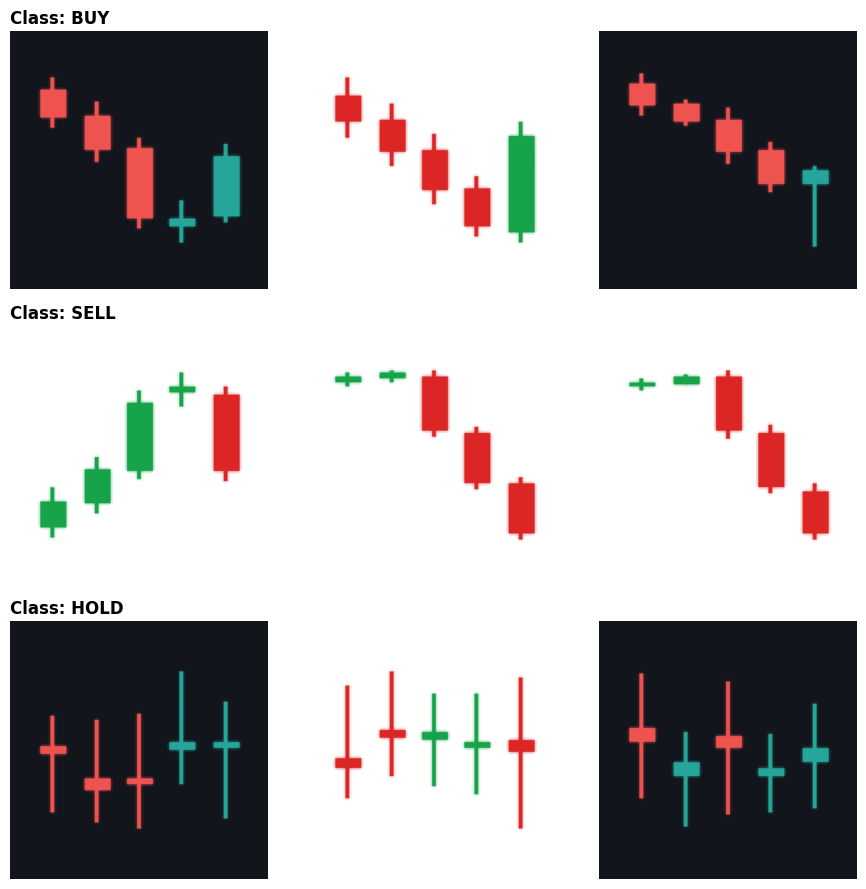

In [10]:
#Visualizing the data generated
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'
classes = ['buy', 'sell', 'hold']

fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row_idx, cls in enumerate(classes):
  cls_folder = os.path.join(data_dir, cls)
  sample_files = random.sample(os.listdir(cls_folder), 3)
  for col_idx, file_name in enumerate(sample_files):
    img_path = os.path.join(cls_folder, file_name)
    img = mpimg.imread(img_path)
    ax = axes[row_idx, col_idx]
    ax.imshow(img)
    ax.axis('off')
    if col_idx == 0:
      ax.set_title(f"Class: {cls.upper()}", fontsize=12, fontweight='bold', loc='left')
plt.tight_layout()
plt.show()

In [11]:
#Feeding the fetched data into the model
import tensorflow as tf
from tensorflow.keras.models import load_model

model = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'
model = load_model(model)

print ("Model loaded successfully")
class_names = ['buy', 'hold', 'sell']
if df_stock is not None and not df_stock.empty and len(df_stock) >= 5:
  recent_candles = df_stock.tail(5)
  candles_tuple = [(row['Open'], row['High'], row['Low'], row['Close']) for _, row in recent_candles.iterrows()]
  #REndering into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles_tuple):
    color = '#16a34a' if c>= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    lower = min(o, c)
    height = max(abs(c - o), 0.15)
    rect = patches.Rectangle((idx - 0.28, lower), 0.56, height, facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  all_lows = [x[2] for x in candles_tuple]
  all_highs = [x[1] for x in candles_tuple]
  pad = (max(all_highs) - min(all_lows)) * 0.15 + 0.5
  ax.set_ylim(min(all_lows) - pad, max(all_highs) + pad)
  ax.set_xlim(-0.7, len(candles_tuple) - 0.3)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Predicting the data to buy/sell/hold
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)

  preds = model.predict(img_array) [0]
  best_idx = preds.argmax()







Model loaded successfully


NameError: name 'df_stock' is not defined

In [17]:
import os
from getpass import getpass
ALPHA_VANTAGE_API_KEY= getpass("Enter your Alpha API Key: ")


Enter your Alpha API Key: ··········


In [19]:
#LOADING LIVE MARKET DATA FROM ALPHA_VANTAGE_STOCK_MARKET
import io
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import yfinance as yf

#Fetching live market data
def fetch_alpha_vantage_data(ticker):
  if not ALPHA_VANTAGE_API_KEY:
    raise ValueError("Alpha Vantage API key not found. Please set the environment variable 'ALPHA_VANTAGE_API_KEY'.")



  print (f"Fetching the data for {ticker}...")
  url = "https://www.alphavantage.co/query"
  params = {
      'function': 'TIME_SERIES_DAILY',
      'symbol': ticker,
      'interval': '5min',
      'outputsize': 'compact',
      'apikey': ALPHA_VANTAGE_API_KEY
  }
  response = requests.get(url, params=params, timeout=30)
  data = response.json()
  time_series = data.get('Time Series (Daily)')


  if time_series is None:
    print("ALpha Vantage did not return market Data")
    print(data.get("Note") or data.get("Information") or data.get("Error Message"))

    return None

    df = pd.DataFrame.from_dict(time_series, orient='index')
    df.index = pd.to_datetime(df.index)
    df.sort_index(inplace = True)

    df.rename(columns={
        '1. open': 'Open',
        '2. high': 'High',
        '3. low': 'Low',
        '4. close': 'Close',
        '5. volume': 'Volume'
    }, inplace=True)
    for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
      df[col] = pd.to_numeric(df[col], errors=coerce)
    return df.dropna()

  #Fetching the data from yfinace for testing
def fetch_yfinance_data(ticker):
    print (f"Fetching the data for {ticker}............")
    df = yf.download(ticker, period="1y", interval="1d", auto_adjust=True, progress=False)
    if df.empty:
        print(f"No data found for {ticker}")
        return None
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df[['Open', 'High', 'Low', 'Close', 'Volume']]
    df = df.dropna()
    print("Yahoo Finance downloaded sucefully..")
    return df

#MERGING THE TWO DATAS FROM ALPHA VANTAGE AND YFINACE

def fetch_market_data(ticker):
  df = fetch_alpha_vantage_data(ticker)

  if df is not None and  not df.empty:
    print("Using ALpha Vantage data...")
    return df
  print ("Trying Yahoo finance instead.....")

  df = fetch_yfinance_data(ticker)
  if df is not None and not df.empty:
    print ("Using Yahoo finance data..")
    return df

  print (f"No market data available for {ticker}..")


#image rendering and saving (Making the telegram function to include even the images)


def render_and_save_tile(candles, path):
  """
  Renders the last 5 candles into a clean 128 * 128 in_memory
  ready to be sent as a photo attachment via telegram"""
  os.makedirs(os.path.dirname(save_path), exist_ok=True)
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)

  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')
  for idx, (o, h, l, c) in enumerate(candles):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    rect = patches.Rectangle(
        (idx - 0.28, min(o, c)),
        0.56,
        max(abs(c - o), 0.15),
        facecolor = color,
        edgecolor=color,
        zorder = 2
    )
    ax.add_patch(rect)
  price_range = max(x[1] for x in candles) - min(x[2] for x in candles)
  pad =price_range * 0.15 + 0.5
  ax.set_ylim(min(x[2] for x in candles) - pad, max(x[1] for x in candles) + pad)
  ax.set_xlim(0.5, len(candles) - 0.5)
  ax.axis('off')
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  fig.savefig(path, format='png', dpi=100, facecolor='#ffffff')
  plt.close("all")






In [20]:
#HISTORICAL LABELLING OF DATA
import yfinance as yf

import os

# Stocks to process
watchlist = ["MSFT"]

# Reset the counter every time this cell runs
total_generated = 0

# Create the three output folders
for folder in ["buy", "hold", "sell"]:
    os.makedirs(os.path.join(output_dir, folder), exist_ok=True)

# Process each stock
for ticker in watchlist:

    # Fetch data ONCE
    df_stock = fetch_market_data(ticker)

    if df_stock is None or len(df_stock) < 10:
        print(f"Insufficient data for {ticker}")
        continue

    source_counts = {"buy": 0, "hold": 0, "sell": 0}

    print(f"\nProcessing {ticker}")
    print("Rows fetched:", len(df_stock))

    # Generate historical samples
    for i in range(5, len(df_stock) - 3):

        # Five-candle historical window
        window = df_stock.iloc[i-5:i]

        current_close = float(window.iloc[-1]["Close"])
        future_close = float(df_stock.iloc[i+3]["Close"])

        # Calculate percentage movement
        pct_change = (future_close - current_close) / current_close

        # Determine label
        if pct_change > 0.005:
            label = "buy"

        elif pct_change < -0.005:
            label = "sell"

        else:
            label = "hold"

        # Convert candles into the format required by render_candles
        candles_tuple = list(
            window[["Open", "High", "Low", "Close"]]
            .itertuples(index=False, name=None)
        )

        # Save image in the correct folder
        save_path = os.path.join(
            output_dir,
            label,
            f"{ticker}_{label}_{i}.png"
        )

        render_and_save_tile(candles_tuple, save_path)

        # Update counters
        source_counts[label] += 1
        total_generated += 1

    # Display results
    print("\nLABEL COUNTS")
    print("BUY:", source_counts["buy"])
    print("HOLD:", source_counts["hold"])
    print("SELL:", source_counts["sell"])
    print("TOTAL:", sum(source_counts.values()))

print("\nTOTAL IMAGES GENERATED:", total_generated)


Fetching the data for MSFT...
Trying Yahoo finance instead.....
Fetching the data for MSFT............
Yahoo Finance downloaded sucefully..
Using Yahoo finance data..

Processing MSFT
Rows fetched: 252

LABEL COUNTS
BUY: 107
HOLD: 28
SELL: 109
TOTAL: 244

TOTAL IMAGES GENERATED: 244


In [21]:
print("OUTPUT DIRECTORY:")
print(os.path.abspath(output_dir))

print("\nDIRECTORY EXISTS:", os.path.exists(output_dir))

for label in ["buy", "hold", "sell"]:
    folder = os.path.join(output_dir, label)

    print(f"\n{label.upper()} FOLDER:")
    print("Path:", os.path.abspath(folder))
    print("Exists:", os.path.exists(folder))

    if os.path.exists(folder):
        files = os.listdir(folder)
        print("Total files:", len(files))
        print("First 5 files:", files[:5])

OUTPUT DIRECTORY:
/content/drive/MyDrive/asset_real_dataset

DIRECTORY EXISTS: True

BUY FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/buy
Exists: True
Total files: 107
First 5 files: ['MSFT_buy_6.png', 'MSFT_buy_170.png', 'MSFT_buy_233.png', 'MSFT_buy_177.png', 'MSFT_buy_153.png']

HOLD FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/hold
Exists: True
Total files: 28
First 5 files: ['MSFT_hold_10.png', 'MSFT_hold_87.png', 'MSFT_hold_33.png', 'MSFT_hold_55.png', 'MSFT_hold_204.png']

SELL FOLDER:
Path: /content/drive/MyDrive/asset_real_dataset/sell
Exists: True
Total files: 109
First 5 files: ['MSFT_sell_165.png', 'MSFT_sell_8.png', 'MSFT_sell_166.png', 'MSFT_sell_51.png', 'MSFT_sell_146.png']


In [14]:
for label in ['buy', 'hold', 'sell']:
  folder = os.path.join(output_dir, label)
  images = [f for f in os.listdir(folder) if f.endswith('.png')]
  print(f"{label.upper()}: {len(images)}")


BUY: 1000
HOLD: 1000
SELL: 1000


In [22]:
#Folder creation for separate the live data from the synthetic data
output_dir = "/content/drive/MyDrive/asset_real_dataset"
for label in["buy", "hold", "sell"]:
  os.makedirs(os.path.join(output_dir, label), exist_ok=True)

In [23]:
df_stock = fetch_yfinance_data("MSFT")
print ("Data shape:", df_stock.shape if df_stock is not None else None)
print("Number of rows:", len(df_stock) if df_stock is not None else 0)
if df_stock is not None:
  print(df_stock.head())
  print (df_stock.tail())


Fetching the data for MSFT............
Yahoo Finance downloaded sucefully..
Data shape: (252, 5)
Number of rows: 252
Price             Open        High         Low       Close    Volume
Date                                                                
2025-11-18  491.327499  498.875413  482.807602  489.760406  33815100
2025-11-19  486.100529  491.148988  478.889837  483.144836  23245300
2025-11-20  489.603854  490.458449  472.502358  475.413879  26802500
2025-11-21  475.483461  475.900827  465.317942  469.143677  31769200
2025-11-24  472.005506  473.893522  465.069498  471.011810  34421000
Price             Open        High         Low       Close    Volume
Date                                                                
2026-11-12  521.099976  529.659973  520.000000  523.000000  18644000
2026-11-13  519.750000  526.419983  513.820007  523.880005  26189200
2026-11-16  525.090027  527.950012  516.820007  517.989990  30218600
2026-11-17  514.570007  515.640015  496.510010  506.239

In [24]:
#Checking the data distribution
print("Dataset shape: ", df_stock.shape)
print("\nLatest market data:")
print(df_stock.tail(10))
print ("\nGenerated images:")
for label in ['buy', 'hold', 'sell']:
  folder = os.path.join(output_dir, label)
  total = len(os.listdir(folder))
  print(label.upper(), ":", len(os.listdir(folder)))

Dataset shape:  (252, 5)

Latest market data:
Price             Open        High         Low       Close    Volume
Date                                                                
2026-11-05  554.940002  557.619995  532.679993  535.929993  42507900
2026-11-06  525.690002  538.330017  524.469971  530.609985  26956400
2026-11-09  544.489990  548.280029  538.700012  545.179993  25337400
2026-11-10  542.979980  544.190002  526.369995  533.159973  26940900
2026-11-11  534.239990  534.760010  518.450012  521.130005  29076800
2026-11-12  521.099976  529.659973  520.000000  523.000000  18644000
2026-11-13  519.750000  526.419983  513.820007  523.880005  26189200
2026-11-16  525.090027  527.950012  516.820007  517.989990  30218600
2026-11-17  514.570007  515.640015  496.510010  506.239990  27914600
2026-11-18  505.109985  508.500000  501.859985  503.220001   3653074

Generated images:
BUY : 107
HOLD : 28
SELL : 109


In [25]:
#Notification tab
import io
import smtplib
from email.mime.text import MIMEText
from email.mime.multipart import MIMEMultipart
from email.mime.image import MIMEImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import requests
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
import time
import yfinance as yf
import os
from getpass import getpass


#USing telegram for model configuration and getting the news
TELEGRAM_TOKEN = getpass("ENTER YOUR TELEGRAM TOKEN: ").strip().strip('"').strip("'")
CHAT_ID = getpass("ENTER YOUR TELEGRAm CHAT ID: ").strip().strip('"').strip("'")

CONFIDENCE_THRESHOLD = 70.0

#Tracking the alerts to avoid the repetitions
last_sent_signals ={}
def process_and_alert(ticker, df_stock):
  print (f" Processing started for {ticker}...")
  if df_stock is None or df_stock.empty or len (df_stock) < 5:
    print(f"Insufficient data for {ticker}.")
    return
  recent = df_stock.tail(5)
  latest_close = recent.iloc[-1]['Close']
  candles = list(recent[['Open', 'High', 'Low', 'Close']].itertuples(index=False, name=None))


  #Rendering the charts into memory buffer
  fig, ax = plt.subplots(figsize=(1.28, 1.28), dpi=100)
  fig.patch.set_facecolor('#ffffff')
  ax.set_facecolor('#ffffff')

  for idx, (o, h, l , c) in enumerate(candles):
    color = '#16a34a' if c >= o else '#dc2626'
    ax.plot([idx, idx], [l, h], color=color, linewidth=1.6, zorder=1)
    rect = patches.Rectangle((idx - 0.28, min(o, c)), 0.56, max(abs(c - o), 0.15), facecolor=color, edgecolor=color, zorder=2)
    ax.add_patch(rect)
  pad = (max(x[1] for x in candles) - min(x[2] for x in candles))
  ax.set_ylim(min(x[2] for x in candles) - pad, max(x[1] for x in candles) + pad)
  ax.set_xlim(0.7, len(candles) - 0.3)
  ax.axis("off")
  plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
  buf = io.BytesIO()
  fig.savefig(buf, format='png', dpi=100, facecolor='#ffffff')
  buf.seek(0)
  plt.close(fig)

  #Running the CNN model for prediction
  img = tf.keras.utils.load_img(buf, target_size=(128, 128))
  img_array = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
  predictions = model.predict(img_array, verbose=0) [0]
  predicted_idx = np.argmax(predictions)
  signal = class_names[predicted_idx].upper()
  confidence = predictions[predicted_idx] * 100

  print (f" {ticker} -> {signal} ({confidence:2f}%)")

  #Sending the telegram alert
  if signal in ['BUY', 'HOLD', 'SELL'] and confidence >= CONFIDENCE_THRESHOLD:
    if last_sent_signals.get(ticker) == signal:
      return #Skipping if the exact signal was already sent
    url =  f"https://api.telegram.org/bot{TELEGRAM_TOKEN}/sendPhoto"
    caption = (
        f"🚨 *Trading Alert: {signal}*\n\n"
        f". *Asset: * '{ticker}'\n"
        f". *Confidence: * *{confidence:.2f}%*\n"
        f". *Latest Close:* '{latest_close}' \n\n"
        f"*Model Probabilities:*\n"
        f"🟢 BUY: {predictions[0]*100:.2f}%\n"
        f"🟡 HOLD: {predictions[1]*100:.2f}%\n"
        f"🔴 SELL: {predictions[2]*100:.2f}%\n"
    )
    buf.seek(0)
    files = {"photo": ("candlestick_tile.png", buf, "image/png")}
    data = {"chat_id": CHAT_ID, "caption": caption}

    response = requests.post(url, data=data, files=files, timeout=30)
    print("Telegram Response:", response.json())
    print ("Telegram Respose:", response.text)
    response.raise_for_status()
    if response.json().get("ok"):
      print(f"📲 Telegram alert sent for {ticker}!")
      last_sent_signals[ticker] = signal
  else:
    last_sent_signals[ticker] = None

#Live sanning for the ticker choosen
watchlist = ["MSFT"]
for ticker in watchlist:
  df_stock = fetch_market_data(ticker)
  if df_stock  is not None:
    process_and_alert(ticker, df_stock)
  time.sleep(3)

ENTER YOUR TELEGRAM TOKEN: ··········
ENTER YOUR TELEGRAm CHAT ID: ··········
Fetching the data for MSFT...
Trying Yahoo finance instead.....
Fetching the data for MSFT............
Yahoo Finance downloaded sucefully..
Using Yahoo finance data..
 Processing started for MSFT...
 MSFT -> BUY (93.367889%)
Telegram Response: {'ok': True, 'result': {'message_id': 29, 'from': {'id': 9110780049, 'is_bot': True, 'first_name': 'Technical Assistance Bot', 'username': 'Charts_annalyser_bot'}, 'chat': {'id': 8633134929, 'first_name': 'Villl', 'last_name': 'Sydican', 'username': 'puppet901', 'type': 'private'}, 'date': 1795016011, 'photo': [{'file_id': 'AgACAgQAAxkDAAMdav3FS15T8Og_aCiQkDLf5Pxu6QYAAkURaxuj6PBT5BBRL469z0wBAAMCAANzAAM9BA', 'file_unique_id': 'AQADRRFrG6Po8FN4', 'file_size': 811, 'width': 90, 'height': 90}, {'file_id': 'AgACAgQAAxkDAAMdav3FS15T8Og_aCiQkDLf5Pxu6QYAAkURaxuj6PBT5BBRL469z0wBAAMCAANtAAM9BA', 'file_unique_id': 'AQADRRFrG6Po8FNy', 'file_size': 1598, 'width': 128, 'height': 128}

In [26]:
import os

data_dir = '/content/drive/MyDrive/cnn_candlestick_dataset'

print("📊 Verifying all files in your dataset folders:")
total_files = 0
for cls in ['buy', 'sell', 'hold']:
    cls_path = os.path.join(data_dir, cls)
    if os.path.exists(cls_path):
        files = os.listdir(cls_path)
        print(f"📂 {cls}/ -> {len(files)} total images found")
        total_files += len(files)
    else:
        print(f"⚠️ Folder missing: {cls}")

print(f"\n🎉 Grand Total across all classes: {total_files} images ready for training!")

📊 Verifying all files in your dataset folders:
📂 buy/ -> 1027 total images found
📂 sell/ -> 1036 total images found
📂 hold/ -> 1001 total images found

🎉 Grand Total across all classes: 3064 images ready for training!


In [27]:
#Testing the yfince API
import yfinance as yf
import curl_cffi
print("YFinance version:", yf.__version__)
print("curl_cffi version:", yf.__version__)

ticker = ['AAPL', 'TSLA']


print(f"Fetching data for {ticker}.....")
df = yf.download(ticker, period="1mo", interval="1d",  auto_adjust=True, progress=False)
if df.empty:
  print(f"No data found for {ticker}")
else:
  print("Download succefully!!")
  print(df.head())
  print("Dataset shape:", df.shape)

YFinance version: 1.8.0
curl_cffi version: 1.8.0
Fetching data for ['AAPL', 'TSLA'].....
Download succefully!!
Price            Close                    High                     Low  \
Ticker            AAPL        TSLA        AAPL        TSLA        AAPL   
Date                                                                     
2026-10-19  342.679626  368.059998  345.737301  369.579987  339.861760   
2026-10-20  339.242249  373.709991  342.799543  377.589996  338.442868   
2026-10-21  343.728821  386.470001  344.987874  388.839996  338.572735   
2026-10-22  347.955627  374.579987  348.095505  388.859985  342.020135   
2026-10-23  347.466003  372.220001  351.462966  377.320007  345.487496   

Price                         Open                Volume            
Ticker            TSLA        AAPL        TSLA      AAPL      TSLA  
Date                                                                
2026-10-19  354.470001  340.521263  357.500000  34573200  38817900  
2026-10-20  363.6400

In [28]:
#Testing the curl_cffi
import curl_cffi
print("Version:", curl_cffi.__version__)
print("Location:", curl_cffi.__version__)

#Testing the brower impersation independently
session = curl_cffi.requests.Session(
    impersonate='chrome152'

)
print("chrome 152 impersonation successful!!")

Version: 0.17.0
Location: 0.17.0
chrome 152 impersonation successful!!


In [29]:
import os

model_path = '/content/drive/MyDrive/cnn_candlestick_model_augmented.keras'

if os.path.exists(model_path):
    print("✅ Model file found!")
else:
    print("⚠️ Model file not found at that path. You need to run your training cell first so it can save the model!")

✅ Model file found!


Trading engine 2.It uses the Intelligence System like the GPT-6-ASTRA to read and annalyse the real market data and then send the notification to telegram


In [29]:
!pip install -q groq



In [30]:
##Connectin groq with the MOdel

import os
from getpass import getpass
from groq import Groq

GROQ_API_KEY = getpass("Enter the Groq Api key : ")

#Creating the API client
client = Groq(api_key=GROQ_API_KEY)
print ("Groq client Initialized successfully!")


Enter the Groq Api key : ··········
Groq client Initialized successfully!


In [31]:
#Connection Testing
response = client.chat.completions.create(
    model = "openai/gpt-oss-120b",
    messages =[{
        "role": "user",
        "content": "Hello, how are you?"
    },
     {
         "role": "assistant",
         "content": "Explain what is RSI in stock market analysis"

     }



    ],temperature=0.2)

print (response.choices[0].message.content)


**Relative Strength Index (RSI) – A Quick Guide**

---

## 1. What is RSI?

The **Relative Strength Index (RSI)** is a momentum‑oscillator used in technical analysis to measure the speed and change of price movements.  
- **Formula:**  
  \[
  RSI = 100 - \frac{100}{1 + RS}
  \]  
  where **RS (Relative Strength)** = **Average Gain** ÷ **Average Loss** over a chosen look‑back period (most commonly 14 periods).  

- **Scale:** 0 – 100.  
  - **High values** (typically > 70) suggest the asset may be **overbought**.  
  - **Low values** (typically < 30) suggest the asset may be **oversold**.  

---

## 2. How is RSI Calculated? (Step‑by‑step)

Assume a 14‑day RSI (the default in most charting platforms).

| Step | Description |
|------|-------------|
| **1. Compute price changes** | For each day, calculate **Δ = Close_today – Close_yesterday**. |
| **2. Separate gains & losses** | <ul><li>**Gain** = Δ if Δ > 0, otherwise 0.</li><li>**Loss** = |Δ| if Δ < 0, otherwise 0.</li></ul> |
| **3. 

In [32]:
#Market data fetching from yfinance
ticker = ["MSFT"]
df_model_b = fetch_market_data(ticker)
if df_model_b is not None and not df_model_b.empty:
  print (f"{ticker} data fetched successfullyI")
  print("Dataset shape: ", df_model_b.shape)
  display(df_model_b.tail())
  print ()
  print("\nDataset Information:")
  df_model_b.info()
else:
  print (f"Unable to fetch Data for {ticker}")



Fetching the data for ['MSFT']...
Trying Yahoo finance instead.....
Fetching the data for ['MSFT']............
Yahoo Finance downloaded sucefully..
Using Yahoo finance data..
['MSFT'] data fetched successfullyI
Dataset shape:  (252, 5)


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-11-12,521.099976,529.659973,520.000000,523.000000,18644000
2026-11-13,519.750000,526.419983,513.820007,523.880005,26189200
2026-11-16,525.090027,527.950012,516.820007,517.989990,30218600
2026-11-17,514.570007,515.640015,496.510010,506.239990,27914600
2026-11-18,505.109985,508.500000,501.859985,503.705902,3815091




Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 252 entries, 2025-11-18 to 2026-11-18
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    252 non-null    float64
 1   High    252 non-null    float64
 2   Low     252 non-null    float64
 3   Close   252 non-null    float64
 4   Volume  252 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.8 KB


In [33]:
#Feature Engineering tab
#Calculating the moving Averages ie (SMA)
df_model_b["SMA_20"]= (df_model_b["Close"].rolling(window=20).mean())
df_model_b["SMA_50"] = (df_model_b["Close"].rolling(window=50).mean()) # Fixed typo: df.model_b to df_model_b
print(df_model_b[["Close", "SMA_20", "SMA_50"]].tail(10))

#Calculating the market RSI (Relative strength Index)
delta = df_model_b["Close"].diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
rs = avg_gain / avg_loss
df_model_b["RSI_14"] = 100 - (100 / (1 + rs))
print(df_model_b[["Close", "RSI_14"]].tail(10))

#Calculating the MACD(Momentum and trend direction)
ema_12 = df_model_b["Close"].ewm(span=12, adjust=False).mean()
ema_26 = df_model_b["Close"].ewm(span=26, adjust=False).mean()
df_model_b["MACD"] = ema_12 - ema_26
df_model_b["MACD_SIGNAL"] = (df_model_b["MACD"].ewm(span=9, adjust=False).mean())
df_model_b["MACD_HIST"] = (df_model_b["MACD"] - df_model_b["MACD_SIGNAL"])
print(df_model_b[["Close", "MACD", "MACD_SIGNAL", "MACD_HIST"]].tail(10))

#Feature inspection
print (df_model_b.tail(10))
print("\nDataset dimensions:", df_model_b.shape)

Price            Close      SMA_20      SMA_50
Date                                          
2026-11-05  535.929993  531.630502  516.134801
2026-11-06  530.609985  531.407501  516.645801
2026-11-09  545.179993  531.609000  517.278800
2026-11-10  533.159973  531.094498  517.796199
2026-11-11  521.130005  530.466498  518.198400
2026-11-12  523.000000  529.644498  518.722000
2026-11-13  523.880005  529.385999  518.997200
2026-11-16  517.989990  528.609497  519.362999
2026-11-17  506.239990  527.327997  519.608799
2026-11-18  503.705902  525.865791  519.849917
Price            Close     RSI_14
Date                             
2026-11-05  535.929993  54.455875
2026-11-06  530.609985  52.147724
2026-11-09  545.179993  57.465097
2026-11-10  533.159973  52.301647
2026-11-11  521.130005  47.683692
2026-11-12  523.000000  48.445700
2026-11-13  523.880005  48.823466
2026-11-16  517.989990  46.374122
2026-11-17  506.239990  41.862315
2026-11-18  503.705902  40.937271
Price            Close      

In [34]:
#Preparing the data for groq to interplate
latest = df_model_b.dropna().iloc[-1]
market_data ={
    "ticker":"MSFT",
    "date": str(df_model_b.dropna().index[-1].date()),
    "close": round(float(latest["Close"]),2),
    "volume": int(latest["Volume"]),
    "sma_20": round(float(latest["SMA_20"]),2),
    "sma_50": round(float(latest["SMA_50"]),2),
    "rsi_14": round(float(latest["RSI_14"]),2),
    "macd": round(float(latest["MACD"]),4),
    "macd_signal": round(float(latest["MACD_SIGNAL"]),4),
    "macd_hist": round(float(latest["MACD_HIST"]),4)
}
print ("Market data for groq")

print (market_data)



Market data for groq
{'ticker': 'MSFT', 'date': '2026-11-18', 'close': 503.71, 'volume': 3815091, 'sma_20': 525.87, 'sma_50': 519.85, 'rsi_14': 40.94, 'macd': -2.2956, 'macd_signal': 1.5266, 'macd_hist': -3.8222}


In [35]:
#Feeding the data to groq for analysis
import json
prompt = f"""
You are a professional financial market analyst.
Analyse the following stock market data for {market_data['ticker']}.
Market Data:
{json.dumps(market_data, indent=4)}

Analyse the following:
1. Overall market trend.
2. Moving averages relationship (SMA 20 and SMA 50).
3. RSI Momentum.
4. MACD and MACD signal relationship
5. Trading volume
6. Potential bullish and bearish conditions
7. Main risks and uncertainties.

Finally, provide
- Decision: BUY, SELL, or HOLD.
- Confidence: LOW, MODERATE, or HIGH.
- Trend: BULLISH, BEARISH, or NEUTRAL.
- Reasons supporting your decision.
- Risks to consider

Do not invent missing information.
Do not guarantee future price movements.
If the indicators conflict or evidence is insufficient, prefer HOLD.

Return your response in a clear, structured format
"""

# Using the active 'llama-3.3-70b-versatile' model to resolve the 404 Not Found error
response = client.chat.completions.create(
    model = "openai/gpt-oss-120b",
    messages = [
        {
            "role": "system",
            "content": "You are an analytical financial market assistant. Base your conclusions on the supplied data."
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    temperature=0.2,
    max_tokens = 1800
)

groq_analysis = response.choices[0].message.content
print("=================GROQ MARKET ANALYSIS================")
print(groq_analysis)

=================GROQ MARKET ANALYSIS================
**MSFT – Technical Snapshot (2026‑11‑18)**  

| Indicator | Value | Interpretation |
|-----------|-------|----------------|
| **Close** | 503.71 | Current price |
| **SMA‑20** | 525.87 | 20‑day average above current price |
| **SMA‑50** | 519.85 | 50‑day average above current price |
| **RSI‑14** | 40.94 | Slightly bearish (below 50, above 30) |
| **MACD** | –2.2956 | Negative |
| **MACD Signal** | 1.5266 | Positive |
| **MACD Histogram** | –3.8222 | Negative (divergence) |
| **Volume** | 3,815,091 | Low‑to‑moderate relative to typical MSFT trading activity (historically tens of millions) |

---

### 1. Overall Market Trend
- The price is **below both the 20‑day and 50‑day SMAs**, indicating a short‑term downtrend within a broader downtrend.
- MACD is negative and below its signal line, reinforcing bearish momentum.
- RSI is under 50, suggesting more sellers than buyers, though not yet oversold.

**Conclusion:** The prevailing techn

In [36]:
#DECISION EXTRACTION
import re
decision_match = re.search(
     r"\*\*Decision\*\*\s*\|\s*\*\*(BUY|SELL|HOLD)\*\*",
     groq_analysis,
     re.IGNORECASE
)

#Confidence extraction
confidence_match = re.search(
    r"\*\*Confidence\*\*\s*\|\s*\*\*(LOW|MODERATE|HIGH)\*\*",
    groq_analysis,
    re.IGNORECASE
)
#Extracting the trend
trend_match = re.search(
    r"\*\*Trend\*\*\s*\|\s*\*\*(BULLISH|BEARISH|NEUTRAL)\*\*",
    groq_analysis,
    re.IGNORECASE
)

#Storing the extracted values
groq_decision = decision_match.group(1).upper() if decision_match else "UNKNOWN"
groq_confidence = confidence_match.group(1).upper() if confidence_match else "UNKNOWN"

groq_trend = trend_match.group(1).upper() if trend_match else "UNKNOWN"

#Extracted results from groq Analysis
print ("===========Results========")
print ("Ticker: ", market_data["ticker"])
print("Decision: ", groq_decision)
print("Confidence: ", groq_confidence)
print("Trend:", groq_trend)


===========Results========
Ticker:  MSFT
Decision:  UNKNOWN
Confidence:  UNKNOWN
Trend: UNKNOWN
